<a href="https://colab.research.google.com/github/Kr-Suryansh/BIS_LAB/blob/main/PSO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration 0: Best Fitness = 10173.14
Iteration 50: Best Fitness = 170.06
Iteration 100: Best Fitness = 170.06
Iteration 150: Best Fitness = 165.11
Iteration 200: Best Fitness = 163.88
Iteration 250: Best Fitness = 163.85

========== OPTIMIZED DRONE ROUTE ==========
Point 1: (5.00, 5.00)
Point 2: (65.00, 10.00)
Point 3: (100.00, 100.00)
Point 4: (100.00, 100.00)
Point 5: (100.00, 100.00)
Point 6: (95.00, 95.00)

Total Distance: 163.85
Status: Collision-free route found!


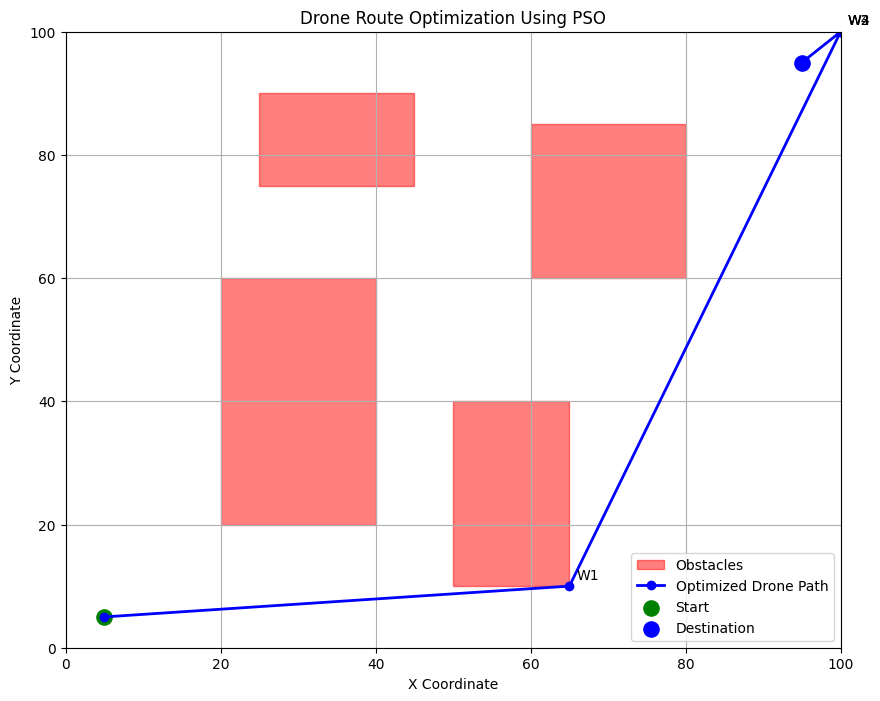

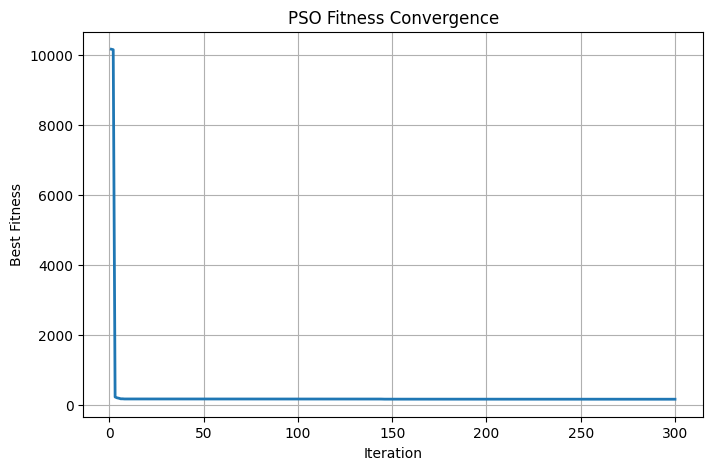

In [3]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. DRONE ENVIRONMENT
# ==========================================

np.random.seed(42)

START = np.array([5, 5])
GOAL = np.array([95, 95])

# Rectangular obstacles: xmin, ymin, xmax, ymax
obstacles = [
    [20, 20, 40, 60],
    [50, 10, 65, 40],
    [60, 60, 80, 85],
    [25, 75, 45, 90]
]

N_WAYPOINTS = 4

# ==========================================
# 2. PSO PARAMETERS
# ==========================================

N_PARTICLES = 60
MAX_ITER = 300

W = 0.7
C1 = 1.5
C2 = 1.5

DIM = N_WAYPOINTS * 2

LOWER = 0
UPPER = 100

COLLISION_COST = 10000

# ==========================================
# 3. COLLISION DETECTION
# ==========================================

def is_inside(point, obstacle):

    xmin, ymin, xmax, ymax = obstacle

    return (
        xmin <= point[0] <= xmax and
        ymin <= point[1] <= ymax
    )


# Check whether a line segment intersects a rectangle
def segment_collision(p1, p2, obstacle):

    xmin, ymin, xmax, ymax = obstacle

    direction = p2 - p1

    t_min = 0.0
    t_max = 1.0

    for axis, lower, upper in [
        (0, xmin, xmax),
        (1, ymin, ymax)
    ]:

        if abs(direction[axis]) < 1e-12:

            if p1[axis] < lower or p1[axis] > upper:
                return False

        else:

            t1 = (lower - p1[axis]) / direction[axis]
            t2 = (upper - p1[axis]) / direction[axis]

            t_enter = min(t1, t2)
            t_exit = max(t1, t2)

            t_min = max(t_min, t_enter)
            t_max = min(t_max, t_exit)

            if t_min > t_max:
                return False

    return True


def collision_penalty(path):

    penalty = 0

    for i in range(len(path) - 1):

        p1 = path[i]
        p2 = path[i + 1]

        for obstacle in obstacles:

            if segment_collision(p1, p2, obstacle):
                penalty += COLLISION_COST

    return penalty


# ==========================================
# 4. FITNESS FUNCTION
# ==========================================

def fitness(position):

    waypoints = position.reshape(N_WAYPOINTS, 2)

    path = np.vstack((START, waypoints, GOAL))

    # Calculate total distance
    distance = 0

    for i in range(len(path) - 1):

        distance += np.linalg.norm(
            path[i + 1] - path[i]
        )

    # Calculate collision penalty
    penalty = collision_penalty(path)

    return distance + penalty


# ==========================================
# 5. INITIALIZE PARTICLES
# ==========================================

positions = np.random.uniform(
    LOWER, UPPER,
    (N_PARTICLES, DIM)
)

velocities = np.random.uniform(
    -5, 5,
    (N_PARTICLES, DIM)
)

personal_best = positions.copy()

personal_fitness = np.array([
    fitness(p) for p in positions
])

best_index = np.argmin(personal_fitness)

global_best = personal_best[best_index].copy()

global_fitness = personal_fitness[best_index]

history = []

# ==========================================
# 6. PARTICLE SWARM OPTIMIZATION
# ==========================================

for iteration in range(MAX_ITER):

    for i in range(N_PARTICLES):

        r1 = np.random.rand(DIM)
        r2 = np.random.rand(DIM)

        # Update velocity
        velocities[i] = (
            W * velocities[i]
            + C1 * r1 * (
                personal_best[i] - positions[i]
            )
            + C2 * r2 * (
                global_best - positions[i]
            )
        )

        # Update position
        positions[i] += velocities[i]

        # Keep particles within boundaries
        positions[i] = np.clip(
            positions[i], LOWER, UPPER
        )

        current_fitness = fitness(positions[i])

        # Update Personal Best
        if current_fitness < personal_fitness[i]:

            personal_fitness[i] = current_fitness

            personal_best[i] = positions[i].copy()

        # Update Global Best
        if current_fitness < global_fitness:

            global_fitness = current_fitness

            global_best = positions[i].copy()

    history.append(global_fitness)

    if iteration % 50 == 0:

        print(
            f"Iteration {iteration}: "
            f"Best Fitness = {global_fitness:.2f}"
        )


# ==========================================
# 7. GET OPTIMIZED DRONE ROUTE
# ==========================================

best_waypoints = global_best.reshape(
    N_WAYPOINTS, 2
)

best_path = np.vstack((
    START,
    best_waypoints,
    GOAL
))

print("\n========== OPTIMIZED DRONE ROUTE ==========")

for i, point in enumerate(best_path):

    print(
        f"Point {i + 1}: "
        f"({point[0]:.2f}, {point[1]:.2f})"
    )

total_distance = sum(
    np.linalg.norm(best_path[i + 1] - best_path[i])
    for i in range(len(best_path) - 1)
)

print("\nTotal Distance:", round(total_distance, 2))

if collision_penalty(best_path) == 0:

    print("Status: Collision-free route found!")

else:

    print("Status: No collision-free route found.")
    print("Try increasing particles or iterations.")


# ==========================================
# 8. VISUALIZE OPTIMIZED DRONE ROUTE
# ==========================================

plt.figure(figsize=(10, 8))

# Draw obstacles
for i, obstacle in enumerate(obstacles):

    xmin, ymin, xmax, ymax = obstacle

    plt.fill(
        [xmin, xmax, xmax, xmin],
        [ymin, ymin, ymax, ymax],
        color='red',
        alpha=0.5,
        label='Obstacles' if i == 0 else ""
    )

# Draw optimized path
plt.plot(
    best_path[:, 0],
    best_path[:, 1],
    'b-o',
    linewidth=2,
    markersize=6,
    label='Optimized Drone Path'
)

# Start and destination
plt.scatter(
    *START,
    color='green',
    s=120,
    label='Start'
)

plt.scatter(
    *GOAL,
    color='blue',
    s=120,
    label='Destination'
)

# Mark waypoints
for i, point in enumerate(best_waypoints):

    plt.annotate(
        f'W{i+1}',
        (point[0], point[1]),
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.title("Drone Route Optimization Using PSO")

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.grid(True)
plt.legend()
plt.show()


# ==========================================
# 9. FITNESS CONVERGENCE GRAPH
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, MAX_ITER + 1),
    history,
    linewidth=2
)

plt.title("PSO Fitness Convergence")

plt.xlabel("Iteration")
plt.ylabel("Best Fitness")

plt.grid(True)
plt.show()
